<a href="https://colab.research.google.com/github/moiz-shahid/Deep-Learning-Tutorials/blob/main/Tutorial-09-SSD-YOLO-Object-Detection/DL_Tutorial_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F

import numpy as np
import matplotlib.pyplot as plt

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

torch.manual_seed(42)

print("PyTorch:", torch.__version__)
print("Device:", device)


PyTorch: 2.14.1+cu130
Device: cuda


In [2]:
class SSDBackbone(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(

            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU()
        )

    def forward(self, x):
        return self.features(x)


ssd_backbone = SSDBackbone().to(device)

print(ssd_backbone)

SSDBackbone(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
  )
)


In [3]:
ssd_dummy_input = torch.randn(
    1, 3, 300, 300
).to(device)

with torch.no_grad():
    ssd_features = ssd_backbone(ssd_dummy_input)

print("Input:", ssd_dummy_input.shape)
print("Backbone output:", ssd_features.shape)

Input: torch.Size([1, 3, 300, 300])
Backbone output: torch.Size([1, 128, 75, 75])


In [4]:
class SSDHead(nn.Module):

    def __init__(self, in_channels, num_classes=21, num_boxes=6):
        super().__init__()

        self.num_classes = num_classes
        self.num_boxes = num_boxes

        self.class_head = nn.Conv2d(
            in_channels,
            num_boxes * num_classes,
            kernel_size=3,
            padding=1
        )

        self.box_head = nn.Conv2d(
            in_channels,
            num_boxes * 4,
            kernel_size=3,
            padding=1
        )

    def forward(self, x):

        batch_size = x.shape[0]

        class_output = self.class_head(x)
        box_output = self.box_head(x)

        # (N, B*C, H, W) -> (N, H*W*B, C)
        class_output = class_output.permute(
            0, 2, 3, 1
        ).contiguous()

        class_output = class_output.reshape(
            batch_size, -1, self.num_classes
        )

        # (N, B*4, H, W) -> (N, H*W*B, 4)
        box_output = box_output.permute(
            0, 2, 3, 1
        ).contiguous()

        box_output = box_output.reshape(
            batch_size, -1, 4
        )

        return class_output, box_output

In [5]:
class CustomSSD(nn.Module):

    def __init__(self, num_classes=21, num_boxes=6):
        super().__init__()

        self.backbone = SSDBackbone()

        # Generate three smaller feature maps
        self.extra_layers = nn.ModuleList([
            nn.Conv2d(128, 128, 3, stride=2, padding=1),
            nn.Conv2d(128, 128, 3, stride=2, padding=1),
            nn.Conv2d(128, 128, 3, stride=2, padding=1)
        ])

        self.detection_heads = nn.ModuleList([
            SSDHead(128, num_classes, num_boxes)
            for _ in range(3)
        ])

    def forward(self, x):

        x = self.backbone(x)

        class_predictions = []
        box_predictions = []

        for extra_layer, head in zip(
            self.extra_layers,
            self.detection_heads
        ):

            x = F.relu(extra_layer(x))

            class_out, box_out = head(x)

            class_predictions.append(class_out)
            box_predictions.append(box_out)

        class_predictions = torch.cat(
            class_predictions, dim=1
        )

        box_predictions = torch.cat(
            box_predictions, dim=1
        )

        return class_predictions, box_predictions


ssd_model = CustomSSD(
    num_classes=21,
    num_boxes=6
).to(device)

print(ssd_model)

CustomSSD(
  (backbone): SSDBackbone(
    (features): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): ReLU()
      (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (7): ReLU()
    )
  )
  (extra_layers): ModuleList(
    (0-2): 3 x Conv2d(128, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
  )
  (detection_heads): ModuleList(
    (0-2): 3 x SSDHead(
      (class_head): Conv2d(128, 126, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (box_head): Conv2d(128, 24, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    )
  )
)


In [6]:
ssd_model.eval()

with torch.no_grad():

    ssd_class_pred, ssd_box_pred = ssd_model(
        ssd_dummy_input
    )

print("SSD Classification Shape:", ssd_class_pred.shape)
print("SSD Bounding Box Shape:", ssd_box_pred.shape)

SSD Classification Shape: torch.Size([1, 11430, 21])
SSD Bounding Box Shape: torch.Size([1, 11430, 4])


In [7]:
class YOLOBackbone(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(

            # Block 1
            nn.Conv2d(3, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 2
            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 3
            nn.Conv2d(64, 128, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 4
            nn.Conv2d(128, 256, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 5
            nn.Conv2d(256, 512, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

    def forward(self, x):
        return self.features(x)


yolo_backbone = YOLOBackbone().to(device)

print(yolo_backbone)

YOLOBackbone(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(256, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU()
    (14): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
)


In [8]:
class YOLOHead(nn.Module):

    def __init__(self, in_channels=512, num_classes=20, num_boxes=3):
        super().__init__()

        self.num_classes = num_classes
        self.num_boxes = num_boxes

        self.prediction = nn.Conv2d(
            in_channels,
            num_boxes * (num_classes + 5),
            kernel_size=1
        )

    def forward(self, x):

        x = self.prediction(x)

        batch_size, channels, height, width = x.shape

        # NCHW -> NHWC
        x = x.permute(0, 2, 3, 1).contiguous()

        x = x.reshape(
            batch_size,
            height,
            width,
            self.num_boxes,
            self.num_classes + 5
        )

        return x

In [9]:
class CustomYOLO(nn.Module):

    def __init__(self, num_classes=20, num_boxes=3):
        super().__init__()

        self.backbone = YOLOBackbone()

        self.head = YOLOHead(
            in_channels=512,
            num_classes=num_classes,
            num_boxes=num_boxes
        )

    def forward(self, x):

        features = self.backbone(x)

        predictions = self.head(features)

        return predictions


yolo_model = CustomYOLO(
    num_classes=20,
    num_boxes=3
).to(device)

print(yolo_model)

CustomYOLO(
  (backbone): YOLOBackbone(
    (features): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): ReLU()
      (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (7): ReLU()
      (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (9): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (10): ReLU()
      (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (12): Conv2d(256, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (13): ReLU()
      (14): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
  )
  (head)

In [10]:
yolo_dummy_input = torch.randn(
    1, 3, 416, 416
).to(device)

yolo_model.eval()

with torch.no_grad():

    yolo_predictions = yolo_model(
        yolo_dummy_input
    )

print("Input Shape:", yolo_dummy_input.shape)
print("YOLO Prediction Shape:", yolo_predictions.shape)

Input Shape: torch.Size([1, 3, 416, 416])
YOLO Prediction Shape: torch.Size([1, 13, 13, 3, 25])


In [11]:
def count_parameters(model):
    return sum(
        p.numel()
        for p in model.parameters()
    )


print("MODEL COMPARISON")
print("-" * 50)

print("SSD Parameters:",
      f"{count_parameters(ssd_model):,}")

print("YOLO Parameters:",
      f"{count_parameters(yolo_model):,}")

print("\nSSD Class Output:", tuple(ssd_class_pred.shape))
print("SSD Box Output:", tuple(ssd_box_pred.shape))

print("YOLO Output:", tuple(yolo_predictions.shape))

MODEL COMPARISON
--------------------------------------------------
SSD Parameters: 1,054,850
YOLO Parameters: 1,607,051

SSD Class Output: (1, 11430, 21)
SSD Box Output: (1, 11430, 4)
YOLO Output: (1, 13, 13, 3, 25)


#Task 1: Train Custom SSD and YOLO on the Bottle Dataset

In [12]:
from google.colab import files
import os
import zipfile

uploaded = files.upload()

zip_filename = next(
    name for name in uploaded
    if name.lower().endswith(".zip")
)

extract_dir = "/content/tutorial9_data"

os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(zip_filename, "r") as zip_ref:
    zip_ref.extractall(extract_dir)

dataset_root = os.path.join(extract_dir, "BottleDataset")

images_dir = os.path.join(dataset_root, "images")
labels_dir = os.path.join(dataset_root, "labels")

print("Images:", len(os.listdir(images_dir)))
print("Labels:", len(os.listdir(labels_dir)))

Saving BottleDataset_150_Clean.zip to BottleDataset_150_Clean.zip
Images: 150
Labels: 150


In [13]:
import torch
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision.transforms import functional as TF
from PIL import Image
from pathlib import Path

class BottleDataset(Dataset):

    def __init__(self, images_dir, labels_dir, image_size):
        self.images_dir = Path(images_dir)
        self.labels_dir = Path(labels_dir)
        self.image_size = image_size

        self.images = sorted([
            p for p in self.images_dir.iterdir()
            if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
        ])

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):

        image_path = self.images[idx]
        label_path = self.labels_dir / (image_path.stem + ".txt")

        image = Image.open(image_path).convert("RGB")
        image = image.resize((self.image_size, self.image_size))

        boxes = []

        with open(label_path, "r") as f:
            for line in f:
                if not line.strip():
                    continue

                cls, xc, yc, w, h = map(float, line.split())

                if int(cls) != 0:
                    raise ValueError("Expected bottle class ID 0")

                if w > 0 and h > 0:
                    boxes.append([xc, yc, w, h])

        boxes = torch.tensor(
            boxes, dtype=torch.float32
        ).reshape(-1, 4)

        return TF.to_tensor(image), boxes


ssd_dataset = BottleDataset(
    images_dir, labels_dir, image_size=300
)

yolo_dataset = BottleDataset(
    images_dir, labels_dir, image_size=416
)

print("SSD dataset:", len(ssd_dataset))
print("YOLO dataset:", len(yolo_dataset))

SSD dataset: 150
YOLO dataset: 150


In [14]:
from sklearn.model_selection import train_test_split
import numpy as np
import random

SEED = 42

torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

indices = list(range(len(ssd_dataset)))

train_idx, remaining_idx = train_test_split(
    indices, test_size=0.30, random_state=SEED
)

val_idx, test_idx = train_test_split(
    remaining_idx, test_size=0.50, random_state=SEED
)

def detection_collate(batch):
    images, boxes = zip(*batch)
    return torch.stack(images), list(boxes)

def make_loader(dataset, indices, shuffle=False):
    return DataLoader(
        Subset(dataset, indices),
        batch_size=2,
        shuffle=shuffle,
        collate_fn=detection_collate,
        num_workers=2
    )

ssd_train_loader = make_loader(
    ssd_dataset, train_idx, shuffle=True
)

ssd_val_loader = make_loader(ssd_dataset, val_idx)
ssd_test_loader = make_loader(ssd_dataset, test_idx)

yolo_train_loader = make_loader(
    yolo_dataset, train_idx, shuffle=True
)

yolo_val_loader = make_loader(yolo_dataset, val_idx)
yolo_test_loader = make_loader(yolo_dataset, test_idx)

print("Training:", len(train_idx))
print("Validation:", len(val_idx))
print("Testing:", len(test_idx))

Training: 105
Validation: 22
Testing: 23


In [15]:
# Reuse CustomSSD and CustomYOLO from earlier cells

torch.manual_seed(42)

ssd_bottle_model = CustomSSD(
    num_classes=2,
    num_boxes=6
).to(device)

torch.manual_seed(42)

yolo_bottle_model = CustomYOLO(
    num_classes=1,
    num_boxes=3
).to(device)

print("SSD and YOLO initialized!")

with torch.no_grad():

    ssd_cls, ssd_box = ssd_bottle_model(
        torch.randn(1, 3, 300, 300).to(device)
    )

    yolo_pred = yolo_bottle_model(
        torch.randn(1, 3, 416, 416).to(device)
    )

print("SSD classes:", ssd_cls.shape)
print("SSD boxes:", ssd_box.shape)
print("YOLO:", yolo_pred.shape)

SSD and YOLO initialized!
SSD classes: torch.Size([1, 11430, 2])
SSD boxes: torch.Size([1, 11430, 4])
YOLO: torch.Size([1, 13, 13, 3, 6])


In [16]:
import math
from torchvision.ops import box_iou

def cxcywh_to_xyxy(boxes):

    cx, cy, w, h = boxes.unbind(-1)

    return torch.stack([
        cx - w / 2,
        cy - h / 2,
        cx + w / 2,
        cy + h / 2
    ], dim=-1)


def generate_ssd_anchors(device):

    sizes = [38, 19, 10]
    scales = [0.1, 0.2, 0.4]
    ratios = [0.5, 1.0, 2.0]

    anchors = []

    for size, scale in zip(sizes, scales):

        for y in range(size):
            for x in range(size):

                cx = (x + 0.5) / size
                cy = (y + 0.5) / size

                for scale_factor in [1.0, 1.5]:
                    for ratio in ratios:

                        w = scale * scale_factor * math.sqrt(ratio)
                        h = scale * scale_factor / math.sqrt(ratio)

                        anchors.append([cx, cy, w, h])

    return torch.tensor(
        anchors,
        dtype=torch.float32,
        device=device
    )


ssd_anchors = generate_ssd_anchors(device)

print("Total SSD anchors:", len(ssd_anchors))

assert len(ssd_anchors) == 11430

Total SSD anchors: 11430


In [17]:
def encode_ssd_boxes(gt_boxes, anchors):

    # Both inputs are [N,4] in cxcywh format

    xy = (gt_boxes[:, :2] - anchors[:, :2]) / anchors[:, 2:]

    wh = torch.log(
        gt_boxes[:, 2:].clamp(min=1e-6) /
        anchors[:, 2:].clamp(min=1e-6)
    )

    return torch.cat([xy, wh], dim=1)


def ssd_loss(class_preds, box_preds, gt_batch, anchors):

    total_cls = class_preds.new_tensor(0.0)
    total_box = box_preds.new_tensor(0.0)

    anchor_xyxy = cxcywh_to_xyxy(anchors)

    batch_size = class_preds.shape[0]

    for b in range(batch_size):

        gt = gt_batch[b].to(class_preds.device)

        num_anchors = len(anchors)

        labels = torch.zeros(
            num_anchors,
            dtype=torch.long,
            device=class_preds.device
        )

        matched_boxes = anchors.clone()

        if len(gt) > 0:

            gt_xyxy = cxcywh_to_xyxy(gt)

            ious = box_iou(anchor_xyxy, gt_xyxy)

            best_iou, best_gt_idx = ious.max(dim=1)

            # Positive anchors
            positive = best_iou >= 0.35

            # Ensure every GT has at least one assigned anchor
            best_anchor_per_gt = ious.argmax(dim=0)

            positive[best_anchor_per_gt] = True

            best_gt_idx[best_anchor_per_gt] = torch.arange(
                len(gt), device=gt.device
            )

            labels[positive] = 1

            matched_boxes = gt[best_gt_idx]

        else:
            positive = torch.zeros(
                num_anchors,
                dtype=torch.bool,
                device=class_preds.device
            )

        # Classification loss per anchor
        cls_losses = F.cross_entropy(
            class_preds[b],
            labels,
            reduction="none"
        )

        num_pos = int(positive.sum().item())

        # Select hardest negative anchors
        negative_losses = cls_losses.clone()
        negative_losses[positive] = -1

        num_neg = min(
            max(3 * num_pos, 10),
            num_anchors - num_pos
        )

        negative_indices = negative_losses.topk(num_neg).indices

        selected = positive.clone()
        selected[negative_indices] = True

        cls_loss = cls_losses[selected].sum() / max(num_pos, 1)

        if num_pos > 0:

            encoded_targets = encode_ssd_boxes(
                matched_boxes[positive],
                anchors[positive]
            )

            box_loss = F.smooth_l1_loss(
                box_preds[b][positive],
                encoded_targets,
                reduction="sum"
            ) / num_pos

        else:
            box_loss = class_preds.new_tensor(0.0)

        total_cls += cls_loss
        total_box += box_loss

    return (total_cls + total_box) / batch_size

In [18]:
YOLO_ANCHORS = torch.tensor([
    [0.08, 0.16],
    [0.20, 0.35],
    [0.40, 0.65]
], dtype=torch.float32, device=device)


def yolo_loss(predictions, gt_batch):

    B, S, _, A, D = predictions.shape

    device_ = predictions.device

    obj_target = torch.zeros(
        (B, S, S, A),
        device=device_
    )

    box_target = torch.zeros(
        (B, S, S, A, 4),
        device=device_
    )

    for b in range(B):

        gt_boxes = gt_batch[b].to(device_)

        for gt in gt_boxes:

            cx, cy, w, h = gt

            gx = min(int(cx.item() * S), S - 1)
            gy = min(int(cy.item() * S), S - 1)

            gt_wh = torch.stack([w, h])

            # Choose best anchor by width-height IoU
            intersection = torch.minimum(
                YOLO_ANCHORS[:, 0], w
            ) * torch.minimum(
                YOLO_ANCHORS[:, 1], h
            )

            union = (
                YOLO_ANCHORS[:, 0] * YOLO_ANCHORS[:, 1]
                + w * h - intersection
            )

            anchor_order = torch.argsort(
                intersection / union.clamp(min=1e-6),
                descending=True
            )

            # Avoid overwriting an occupied target
            chosen_anchor = None

            for a in anchor_order.tolist():
                if obj_target[b, gy, gx, a] == 0:
                    chosen_anchor = a
                    break

            if chosen_anchor is None:
                continue

            a = chosen_anchor

            obj_target[b, gy, gx, a] = 1.0
            box_target[b, gy, gx, a] = gt

    # Decode predicted boxes
    yy, xx = torch.meshgrid(
        torch.arange(S, device=device_),
        torch.arange(S, device=device_),
        indexing="ij"
    )

    grid = torch.stack([xx, yy], dim=-1)
    grid = grid.view(1, S, S, 1, 2)

    pred_xy = (
        predictions[..., :2].sigmoid() + grid
    ) / S

    pred_wh = (
        predictions[..., 2:4].clamp(-5, 5).exp()
        * YOLO_ANCHORS.view(1, 1, 1, A, 2)
    )

    decoded_boxes = torch.cat(
        [pred_xy, pred_wh], dim=-1
    )

    positive = obj_target == 1

    # Objectness loss
    obj_loss = F.binary_cross_entropy_with_logits(
        predictions[..., 4],
        obj_target,
        reduction="none"
    )

    obj_weights = torch.where(
        positive,
        1.0,
        0.1
    )

    obj_loss = (
        obj_loss * obj_weights
    ).sum() / max(int(positive.sum()), 1)

    if positive.any():

        box_loss = F.smooth_l1_loss(
            decoded_boxes[positive],
            box_target[positive],
            reduction="sum"
        ) / positive.sum()

        # Single foreground class: bottle
        cls_target = torch.ones_like(
            predictions[..., 5][positive]
        )

        cls_loss = F.binary_cross_entropy_with_logits(
            predictions[..., 5][positive],
            cls_target
        )

    else:
        box_loss = predictions.new_tensor(0.0)
        cls_loss = predictions.new_tensor(0.0)

    return obj_loss + 10.0 * box_loss + cls_loss

In [19]:
import time
import copy

def train_detection_model(
    model,
    train_loader,
    val_loader,
    model_type,
    epochs=15,
    lr=0.0001
):

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=lr,
        weight_decay=0.0005
    )

    history = {
        "train_loss": [],
        "val_loss": []
    }

    best_val_loss = float("inf")
    best_weights = None

    for epoch in range(epochs):

        model.train()
        running_loss = 0.0

        start_time = time.time()

        for images, gt_boxes in train_loader:

            images = images.to(device)

            optimizer.zero_grad()

            if model_type == "SSD":

                class_preds, box_preds = model(images)

                loss = ssd_loss(
                    class_preds,
                    box_preds,
                    gt_boxes,
                    ssd_anchors
                )

            else:

                predictions = model(images)

                loss = yolo_loss(
                    predictions,
                    gt_boxes
                )

            if not torch.isfinite(loss):
                raise RuntimeError("Non-finite training loss")

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(), max_norm=5.0
            )

            optimizer.step()

            running_loss += loss.item()

        train_loss = running_loss / len(train_loader)

        # Validation loss
        model.eval()
        running_val_loss = 0.0

        with torch.no_grad():

            for images, gt_boxes in val_loader:

                images = images.to(device)

                if model_type == "SSD":

                    class_preds, box_preds = model(images)

                    loss = ssd_loss(
                        class_preds,
                        box_preds,
                        gt_boxes,
                        ssd_anchors
                    )

                else:

                    predictions = model(images)

                    loss = yolo_loss(
                        predictions,
                        gt_boxes
                    )

                running_val_loss += loss.item()

        val_loss = running_val_loss / len(val_loader)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        if val_loss < best_val_loss:

            best_val_loss = val_loss

            best_weights = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

        elapsed = time.time() - start_time

        print(
            f"{model_type} | Epoch {epoch+1}/{epochs} | "
            f"Train: {train_loss:.4f} | "
            f"Val: {val_loss:.4f} | "
            f"Time: {elapsed:.1f}s"
        )

    if best_weights is not None:
        model.load_state_dict(best_weights)

    print(f"\n{model_type} best validation loss: {best_val_loss:.4f}")

    return model, history

In [20]:
print("TRAINING CUSTOM SSD")

ssd_bottle_model, ssd_history = train_detection_model(
    model=ssd_bottle_model,
    train_loader=ssd_train_loader,
    val_loader=ssd_val_loader,
    model_type="SSD",
    epochs=15,
    lr=0.0001
)

TRAINING CUSTOM SSD
SSD | Epoch 1/15 | Train: 2.9805 | Val: 2.8324 | Time: 3.2s
SSD | Epoch 2/15 | Train: 2.6415 | Val: 2.4187 | Time: 3.0s
SSD | Epoch 3/15 | Train: 2.4026 | Val: 2.3503 | Time: 2.5s
SSD | Epoch 4/15 | Train: 2.3706 | Val: 2.3476 | Time: 1.7s
SSD | Epoch 5/15 | Train: 2.3565 | Val: 2.3473 | Time: 1.7s
SSD | Epoch 6/15 | Train: 2.3489 | Val: 2.3345 | Time: 2.8s
SSD | Epoch 7/15 | Train: 2.3433 | Val: 2.3189 | Time: 2.2s
SSD | Epoch 8/15 | Train: 2.3479 | Val: 2.3181 | Time: 3.3s
SSD | Epoch 9/15 | Train: 2.3285 | Val: 2.3098 | Time: 1.7s
SSD | Epoch 10/15 | Train: 2.3203 | Val: 2.2975 | Time: 1.7s
SSD | Epoch 11/15 | Train: 2.3160 | Val: 2.2942 | Time: 1.7s
SSD | Epoch 12/15 | Train: 2.3071 | Val: 2.2832 | Time: 1.7s
SSD | Epoch 13/15 | Train: 2.2922 | Val: 2.2599 | Time: 2.2s
SSD | Epoch 14/15 | Train: 2.2730 | Val: 2.2514 | Time: 3.3s
SSD | Epoch 15/15 | Train: 2.2384 | Val: 2.2002 | Time: 2.1s

SSD best validation loss: 2.2002


In [21]:
print("TRAINING CUSTOM YOLO")

yolo_bottle_model, yolo_history = train_detection_model(
    model=yolo_bottle_model,
    train_loader=yolo_train_loader,
    val_loader=yolo_val_loader,
    model_type="YOLO",
    epochs=15,
    lr=0.0001
)

TRAINING CUSTOM YOLO
YOLO | Epoch 1/15 | Train: 16.4437 | Val: 4.9925 | Time: 2.3s
YOLO | Epoch 2/15 | Train: 4.5774 | Val: 4.1360 | Time: 2.6s
YOLO | Epoch 3/15 | Train: 4.2488 | Val: 3.9718 | Time: 2.2s
YOLO | Epoch 4/15 | Train: 4.1851 | Val: 3.9176 | Time: 4.0s
YOLO | Epoch 5/15 | Train: 4.1389 | Val: 3.8933 | Time: 2.1s
YOLO | Epoch 6/15 | Train: 4.0469 | Val: 3.7780 | Time: 2.0s
YOLO | Epoch 7/15 | Train: 4.0796 | Val: 3.8124 | Time: 2.5s
YOLO | Epoch 8/15 | Train: 4.0104 | Val: 3.8631 | Time: 2.1s
YOLO | Epoch 9/15 | Train: 4.0058 | Val: 3.7199 | Time: 2.8s
YOLO | Epoch 10/15 | Train: 3.9792 | Val: 3.8012 | Time: 2.4s
YOLO | Epoch 11/15 | Train: 3.9566 | Val: 3.6999 | Time: 2.1s
YOLO | Epoch 12/15 | Train: 3.9472 | Val: 3.8065 | Time: 2.6s
YOLO | Epoch 13/15 | Train: 3.9640 | Val: 3.6628 | Time: 2.0s
YOLO | Epoch 14/15 | Train: 3.9281 | Val: 3.7612 | Time: 2.1s
YOLO | Epoch 15/15 | Train: 4.0209 | Val: 3.6590 | Time: 3.2s

YOLO best validation loss: 3.6590


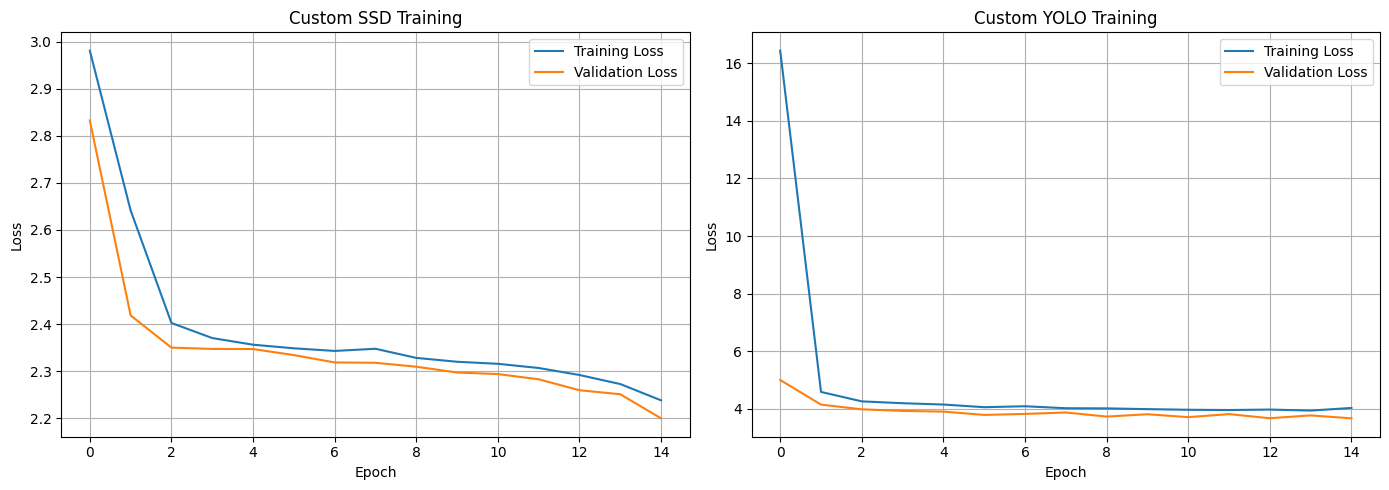

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    ssd_history["train_loss"],
    label="Training Loss"
)

axes[0].plot(
    ssd_history["val_loss"],
    label="Validation Loss"
)

axes[0].set_title("Custom SSD Training")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    yolo_history["train_loss"],
    label="Training Loss"
)

axes[1].plot(
    yolo_history["val_loss"],
    label="Validation Loss"
)

axes[1].set_title("Custom YOLO Training")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [23]:
from torchvision.ops import nms

def postprocess_detections(boxes, scores, threshold=0.05):

    boxes = boxes.clamp(0, 1)

    valid = (
        (boxes[:, 2] > boxes[:, 0]) &
        (boxes[:, 3] > boxes[:, 1]) &
        (scores >= threshold)
    )

    boxes = boxes[valid]
    scores = scores[valid]

    if len(scores) == 0:
        return boxes, scores

    # Restrict proposals before NMS
    topk = scores.argsort(descending=True)[:1000]

    boxes = boxes[topk]
    scores = scores[topk]

    keep = nms(boxes, scores, iou_threshold=0.5)[:100]

    return boxes[keep], scores[keep]


def predict_ssd(model, images):

    model.eval()

    with torch.no_grad():
        class_preds, box_preds = model(images.to(device))

    results = []

    for b in range(len(images)):

        scores = F.softmax(class_preds[b], dim=-1)[:, 1]

        deltas = box_preds[b]

        xy = (
            ssd_anchors[:, :2]
            + deltas[:, :2] * ssd_anchors[:, 2:]
        )

        wh = (
            ssd_anchors[:, 2:]
            * deltas[:, 2:].clamp(-5, 5).exp()
        )

        boxes = cxcywh_to_xyxy(
            torch.cat([xy, wh], dim=-1)
        )

        boxes, scores = postprocess_detections(boxes, scores)

        results.append({
            "boxes": boxes.cpu(),
            "scores": scores.cpu(),
            "labels": torch.ones(
                len(scores), dtype=torch.int64
            )
        })

    return results


def predict_yolo(model, images):

    model.eval()

    with torch.no_grad():
        predictions = model(images.to(device))

    B, S, _, A, _ = predictions.shape

    yy, xx = torch.meshgrid(
        torch.arange(S, device=device),
        torch.arange(S, device=device),
        indexing="ij"
    )

    grid = torch.stack([xx, yy], dim=-1)
    grid = grid.view(1, S, S, 1, 2)

    xy = (
        predictions[..., :2].sigmoid() + grid
    ) / S

    wh = (
        predictions[..., 2:4].clamp(-5, 5).exp()
        * YOLO_ANCHORS.view(1, 1, 1, A, 2)
    )

    scores = (
        predictions[..., 4].sigmoid()
        * predictions[..., 5].sigmoid()
    )

    boxes = cxcywh_to_xyxy(
        torch.cat([xy, wh], dim=-1)
    )

    results = []

    for b in range(B):

        boxes_b = boxes[b].reshape(-1, 4)
        scores_b = scores[b].reshape(-1)

        boxes_b, scores_b = postprocess_detections(
            boxes_b, scores_b
        )

        results.append({
            "boxes": boxes_b.cpu(),
            "scores": scores_b.cpu(),
            "labels": torch.ones(
                len(scores_b), dtype=torch.int64
            )
        })

    return results

In [24]:
!pip -q install torchmetrics pycocotools

In [25]:
from torchmetrics.detection.mean_ap import MeanAveragePrecision

def evaluate_model_map(model, loader, model_type):

    metric = MeanAveragePrecision(
        box_format="xyxy",
        iou_type="bbox"
    )

    for images, gt_boxes in loader:

        if model_type == "SSD":
            predictions = predict_ssd(model, images)
        else:
            predictions = predict_yolo(model, images)

        targets = []

        for boxes in gt_boxes:

            gt_xyxy = cxcywh_to_xyxy(boxes).clamp(0, 1)

            targets.append({
                "boxes": gt_xyxy.cpu(),
                "labels": torch.ones(
                    len(boxes), dtype=torch.int64
                )
            })

        metric.update(predictions, targets)

    results = metric.compute()

    return {
        "map50": results["map_50"].item(),
        "map5095": results["map"].item()
    }


ssd_metrics = evaluate_model_map(
    ssd_bottle_model,
    ssd_test_loader,
    "SSD"
)

yolo_metrics = evaluate_model_map(
    yolo_bottle_model,
    yolo_test_loader,
    "YOLO"
)

print("SSD Results:", ssd_metrics)
print("YOLO Results:", yolo_metrics)

SSD Results: {'map50': 0.6851821541786194, 'map5095': 0.21321412920951843}
YOLO Results: {'map50': 0.057819243520498276, 'map5095': 0.017060507088899612}


In [26]:
import pandas as pd

comparison_df = pd.DataFrame({
    "Model": ["Custom SSD", "Custom YOLO"],
    "Parameters": [
        count_parameters(ssd_bottle_model),
        count_parameters(yolo_bottle_model)
    ],
    "Test mAP@0.5": [
        ssd_metrics["map50"],
        yolo_metrics["map50"]
    ],
    "Test mAP@0.5:0.95": [
        ssd_metrics["map5095"],
        yolo_metrics["map5095"]
    ]
})

display(comparison_df)

,Model,Parameters,Test mAP@0.5,Test mAP@0.5:0.95
0,Custom SSD,660524,0.685182,0.213214
1,Custom YOLO,1577810,0.057819,0.017061


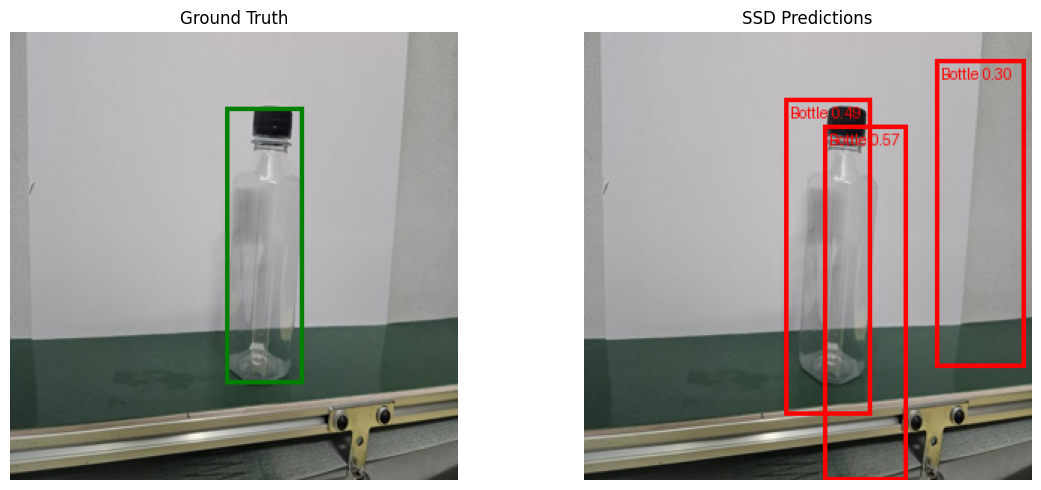

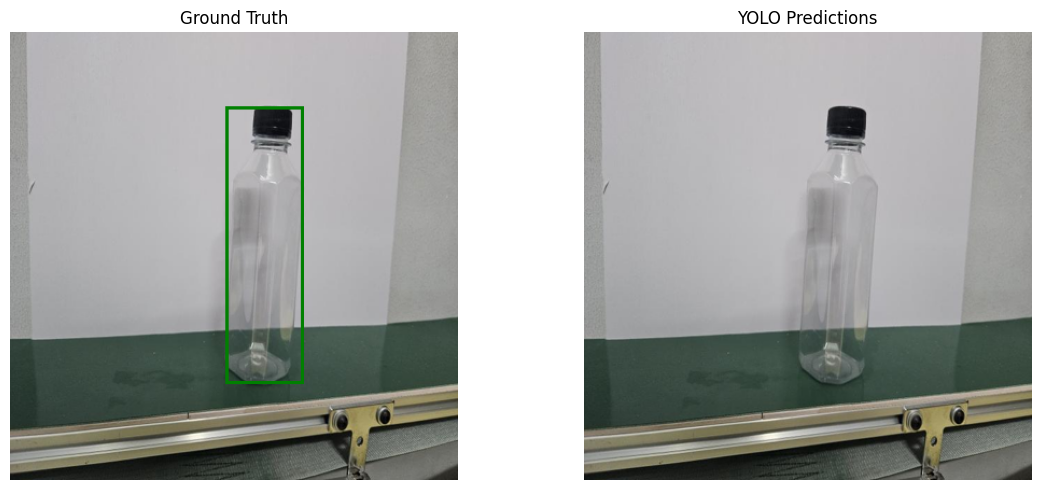

In [27]:
from torchvision.utils import draw_bounding_boxes
from torchvision.transforms.functional import to_pil_image

def show_predictions(model, dataset, model_type, index=0):

    image, gt_boxes = dataset[index]

    if model_type == "SSD":
        predictions = predict_ssd(
            model, image.unsqueeze(0)
        )[0]
    else:
        predictions = predict_yolo(
            model, image.unsqueeze(0)
        )[0]

    image_uint8 = (
        image * 255
    ).clamp(0, 255).to(torch.uint8)

    H, W = image.shape[1:]

    scale = torch.tensor([W, H, W, H])

    gt_xyxy = cxcywh_to_xyxy(gt_boxes) * scale

    pred_boxes = predictions["boxes"] * scale

    gt_image = draw_bounding_boxes(
        image_uint8,
        gt_xyxy,
        colors="green",
        width=3
    )

    keep = predictions["scores"] >= 0.3

    if keep.any():
        pred_image = draw_bounding_boxes(
            image_uint8,
            pred_boxes[keep],
            labels=[
                f"Bottle {s:.2f}"
                for s in predictions["scores"][keep].tolist()
            ],
            colors="red",
            width=3
        )
    else:
        pred_image = image_uint8

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    axes[0].imshow(to_pil_image(gt_image))
    axes[0].set_title("Ground Truth")

    axes[1].imshow(to_pil_image(pred_image))
    axes[1].set_title(f"{model_type} Predictions")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()


ssd_test_dataset = Subset(ssd_dataset, test_idx)
yolo_test_dataset = Subset(yolo_dataset, test_idx)

show_predictions(
    ssd_bottle_model, ssd_test_dataset, "SSD", index=0
)

show_predictions(
    yolo_bottle_model, yolo_test_dataset, "YOLO", index=0
)

In [28]:
import os

save_dir = "/content/tutorial9_task1_results"
os.makedirs(save_dir, exist_ok=True)

torch.save(
    ssd_bottle_model.state_dict(),
    f"{save_dir}/custom_ssd.pth"
)

torch.save(
    yolo_bottle_model.state_dict(),
    f"{save_dir}/custom_yolo.pth"
)

comparison_df.to_csv(
    f"{save_dir}/ssd_yolo_comparison.csv",
    index=False
)

pd.DataFrame(ssd_history).to_csv(
    f"{save_dir}/ssd_history.csv",
    index=False
)

pd.DataFrame(yolo_history).to_csv(
    f"{save_dir}/yolo_history.csv",
    index=False
)

print("Models and results saved.")

Models and results saved.


## Analysis
Both models demonstrated reductions in training and validation loss, indicating that their optimization processes were progressing.

However, SSD achieved substantially higher object detection performance than YOLO.

The SSD model achieved 68.52% mAP@0.5, compared with 5.78% for YOLO.

SSD's use of multi-scale feature maps and its anchor-matching strategy may have contributed to better detection performance under the selected training conditions.

The simplified YOLO model struggled to produce confident detections, potentially due to limited training data, anchor configuration, target assignment, and the simplified detection loss.

The lower mAP@0.5:0.95 scores for both models indicate that precise bounding-box localization remains challenging.

Visual inspection showed that SSD produced several overlapping detections and an incorrect background prediction. YOLO did not produce a visible detection at the selected confidence threshold of 0.3.

Since the two models use different loss formulations and input resolutions, direct numerical comparison of their training losses does not establish which model is better.

# Task 2: Fine-Tuning Pretrained SSD and YOLO

In [29]:
!pip -q install ultralytics torchmetrics pycocotools

In [30]:
import torch
import torchvision

from torchvision.models.detection import (
    ssd300_vgg16,
    SSD300_VGG16_Weights
)

ssd_weights = SSD300_VGG16_Weights.DEFAULT

pretrained_ssd = ssd300_vgg16(
    weights=ssd_weights
).to(device)

# Freeze pretrained feature extractor
for param in pretrained_ssd.backbone.parameters():
    param.requires_grad = False

# Train detection head
for param in pretrained_ssd.head.parameters():
    param.requires_grad = True

SSD_BOTTLE_ID = ssd_weights.meta["categories"].index("bottle")

print("Pretrained SSD loaded!")
print("Bottle class ID:", SSD_BOTTLE_ID)

print(
    "Trainable parameters:",
    sum(
        p.numel()
        for p in pretrained_ssd.parameters()
        if p.requires_grad
    )
)

Downloading: "https://download.pytorch.org/models/ssd300_vgg16_coco-b556d3b4.pth" to /root/.cache/torch/hub/checkpoints/ssd300_vgg16_coco-b556d3b4.pth


100%|██████████| 136M/136M [00:00<00:00, 172MB/s]


Pretrained SSD loaded!
Bottle class ID: 44
Trainable parameters: 12697890


In [31]:
def prepare_ssd_targets(images, gt_boxes):

    targets = []

    H, W = images.shape[-2:]

    scale = torch.tensor(
        [W, H, W, H],
        dtype=torch.float32
    )

    for boxes in gt_boxes:

        # Normalized cxcywh -> normalized xyxy
        xyxy = cxcywh_to_xyxy(boxes)

        # Convert to pixel coordinates
        xyxy = xyxy * scale

        targets.append({
            "boxes": xyxy.to(device),
            "labels": torch.full(
                (len(boxes),),
                SSD_BOTTLE_ID,
                dtype=torch.int64,
                device=device
            )
        })

    return targets

In [32]:
import copy
import time

def train_pretrained_ssd(
    model,
    train_loader,
    val_loader,
    epochs=10
):

    optimizer = torch.optim.Adam(
        filter(
            lambda p: p.requires_grad,
            model.parameters()
        ),
        lr=0.0001,
        weight_decay=0.0005
    )

    history = {
        "train_loss": [],
        "val_loss": []
    }

    best_loss = float("inf")
    best_weights = None

    for epoch in range(epochs):

        model.train()
        running_loss = 0.0
        start = time.time()

        for images, boxes in train_loader:

            images = images.to(device)

            targets = prepare_ssd_targets(
                images, boxes
            )

            optimizer.zero_grad()

            loss_dict = model(
                list(images),
                targets
            )

            loss = sum(loss_dict.values())

            if not torch.isfinite(loss):
                raise RuntimeError("Non-finite SSD loss")

            loss.backward()

            optimizer.step()

            running_loss += loss.item()

        train_loss = running_loss / len(train_loader)

        # Torchvision detection models return
        # losses when in training mode.
        # Disable gradients for validation.
        model.train()
        running_val_loss = 0.0

        with torch.no_grad():

            for images, boxes in val_loader:

                images = images.to(device)

                targets = prepare_ssd_targets(
                    images, boxes
                )

                loss_dict = model(
                    list(images),
                    targets
                )

                loss = sum(loss_dict.values())

                running_val_loss += loss.item()

        val_loss = running_val_loss / len(val_loader)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        if val_loss < best_loss:

            best_loss = val_loss

            best_weights = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Time: {time.time()-start:.1f}s"
        )

    model.load_state_dict(best_weights)
    model.eval()

    print("\nBest validation loss:", round(best_loss, 4))

    return model, history

In [33]:
pretrained_ssd, pretrained_ssd_history = train_pretrained_ssd(
    pretrained_ssd,
    ssd_train_loader,
    ssd_val_loader,
    epochs=10
)

Epoch 1/10 | Train Loss: 1.9544 | Val Loss: 1.2532 | Time: 5.2s
Epoch 2/10 | Train Loss: 1.6102 | Val Loss: 1.1910 | Time: 4.4s
Epoch 3/10 | Train Loss: 1.3865 | Val Loss: 1.1499 | Time: 3.9s
Epoch 4/10 | Train Loss: 1.3460 | Val Loss: 1.1286 | Time: 4.6s
Epoch 5/10 | Train Loss: 1.3038 | Val Loss: 1.1509 | Time: 3.9s
Epoch 6/10 | Train Loss: 1.2164 | Val Loss: 1.0493 | Time: 4.4s
Epoch 7/10 | Train Loss: 1.1993 | Val Loss: 1.0524 | Time: 4.0s
Epoch 8/10 | Train Loss: 1.1310 | Val Loss: 1.0537 | Time: 3.9s
Epoch 9/10 | Train Loss: 1.0212 | Val Loss: 1.0429 | Time: 3.8s
Epoch 10/10 | Train Loss: 1.0789 | Val Loss: 1.0027 | Time: 3.8s

Best validation loss: 1.0027


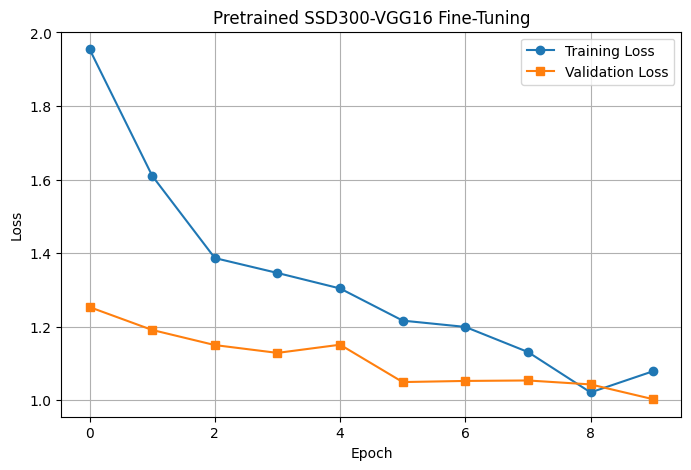

In [34]:
plt.figure(figsize=(8, 5))

plt.plot(
    pretrained_ssd_history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    pretrained_ssd_history["val_loss"],
    marker="s",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Pretrained SSD300-VGG16 Fine-Tuning")
plt.legend()
plt.grid(True)
plt.show()

In [35]:
from torchmetrics.detection.mean_ap import MeanAveragePrecision

def evaluate_pretrained_ssd(model, loader):

    model.eval()

    metric = MeanAveragePrecision(
        box_format="xyxy",
        iou_type="bbox"
    )

    with torch.no_grad():

        for images, gt_boxes in loader:

            images = images.to(device)

            outputs = model(list(images))

            predictions = []
            targets = []

            H, W = images.shape[-2:]
            scale = torch.tensor(
                [W, H, W, H],
                dtype=torch.float32
            )

            for output, gt in zip(outputs, gt_boxes):

                output = {
                    k: v.cpu()
                    for k, v in output.items()
                }

                # Evaluate only the bottle class
                keep = output["labels"] == SSD_BOTTLE_ID

                predictions.append({
                    "boxes": output["boxes"][keep],
                    "scores": output["scores"][keep],
                    "labels": output["labels"][keep]
                })

                targets.append({
                    "boxes": cxcywh_to_xyxy(gt) * scale,
                    "labels": torch.full(
                        (len(gt),),
                        SSD_BOTTLE_ID,
                        dtype=torch.int64
                    )
                })

            metric.update(predictions, targets)

    results = metric.compute()

    return {
        "map50": results["map_50"].item(),
        "map5095": results["map"].item()
    }


pretrained_ssd_metrics = evaluate_pretrained_ssd(
    pretrained_ssd,
    ssd_test_loader
)

print("PRETRAINED SSD TEST RESULTS")
print("-" * 40)

print(
    f"mAP@0.5: {pretrained_ssd_metrics['map50']:.4f}"
)

print(
    f"mAP@0.5:0.95: {pretrained_ssd_metrics['map5095']:.4f}"
)

PRETRAINED SSD TEST RESULTS
----------------------------------------
mAP@0.5: 0.9355
mAP@0.5:0.95: 0.7436


In [36]:
import os
import shutil
from pathlib import Path
import yaml

yolo_root = Path("/content/tutorial9_pretrained_yolo")

for split in ["train", "val", "test"]:
    (yolo_root / "images" / split).mkdir(
        parents=True, exist_ok=True
    )
    (yolo_root / "labels" / split).mkdir(
        parents=True, exist_ok=True
    )

source_images = ssd_dataset.images

splits = {
    "train": train_idx,
    "val": val_idx,
    "test": test_idx
}

for split_name, split_indices in splits.items():

    for idx in split_indices:

        image_path = source_images[idx]
        label_path = Path(labels_dir) / (
            image_path.stem + ".txt"
        )

        if not label_path.exists():
            raise FileNotFoundError(label_path)

        shutil.copy2(
            image_path,
            yolo_root / "images" / split_name / image_path.name
        )

        shutil.copy2(
            label_path,
            yolo_root / "labels" / split_name / label_path.name
        )

data_config = {
    "path": str(yolo_root),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "nc": 1,
    "names": {0: "bottle"}
}

yaml_path = yolo_root / "data.yaml"

with open(yaml_path, "w") as f:
    yaml.safe_dump(data_config, f)

print("YOLO dataset prepared!")

for split in splits:
    print(
        split,
        len(list((yolo_root / "images" / split).iterdir()))
    )

print("\nDataset configuration:")
print(yaml_path.read_text())

YOLO dataset prepared!
train 105
val 22
test 23

Dataset configuration:
names:
  0: bottle
nc: 1
path: /content/tutorial9_pretrained_yolo
test: images/test
train: images/train
val: images/val



In [37]:
from ultralytics import YOLO

pretrained_yolo = YOLO("yolov8n.pt")

yolo_training_results = pretrained_yolo.train(
    data=str(yaml_path),
    epochs=20,
    imgsz=416,
    batch=8,
    patience=7,
    device=0 if torch.cuda.is_available() else "cpu",
    workers=2,
    seed=42,
    project="/content/tutorial9_pretrained_results",
    name="yolov8_bottle",
    exist_ok=True,
    plots=True
)

print("YOLO training completed!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/tutorial9_pretrained_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, f

In [38]:
best_yolo_path = (
    "/content/tutorial9_pretrained_results/"
    "yolov8_bottle/weights/best.pt"
)

best_yolo = YOLO(best_yolo_path)

yolo_test_results = best_yolo.val(
    data=str(yaml_path),
    split="test",
    imgsz=416,
    batch=8,
    device=0 if torch.cuda.is_available() else "cpu",
    plots=True
)

pretrained_yolo_metrics = {
    "map50": float(yolo_test_results.box.map50),
    "map5095": float(yolo_test_results.box.map)
}

print("PRETRAINED YOLO TEST RESULTS")
print("-" * 40)

print(
    f"mAP@0.5: {pretrained_yolo_metrics['map50']:.4f}"
)

print(
    f"mAP@0.5:0.95: {pretrained_yolo_metrics['map5095']:.4f}"
)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1200.8±471.7 MB/s, size: 32.7 KB)
val: Scanning /content/tutorial9_pretrained_yolo/labels/test... 23 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 23/23 2.0Kit/s 0.0s
val: New cache created: /content/tutorial9_pretrained_yolo/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 2.4it/s 1.2s
                   all         23         24          1      0.915      0.948      0.859
Speed: 1.0ms preprocess, 15.8ms inference, 0.0ms loss, 4.3ms postprocess per image
Results saved to /content/runs/detect/val
PRETRAINED YOLO TEST RESULTS
----------------------------------------
mAP@0.5: 0.9479
mAP@0.5:0.95: 0.8589


In [39]:
import pandas as pd

final_comparison = pd.DataFrame({
    "Model": [
        "Custom SSD",
        "Pretrained SSD300-VGG16",
        "Custom YOLO",
        "Pretrained YOLOv8n"
    ],

    "mAP@0.5": [
        ssd_metrics["map50"],
        pretrained_ssd_metrics["map50"],
        yolo_metrics["map50"],
        pretrained_yolo_metrics["map50"]
    ],

    "mAP@0.5:0.95": [
        ssd_metrics["map5095"],
        pretrained_ssd_metrics["map5095"],
        yolo_metrics["map5095"],
        pretrained_yolo_metrics["map5095"]
    ]
})

display(final_comparison)

,Model,mAP@0.5,mAP@0.5:0.95
0,Custom SSD,0.685182,0.213214
1,Pretrained SSD300-VGG16,0.935522,0.743620
2,Custom YOLO,0.057819,0.017061
3,Pretrained YOLOv8n,0.947857,0.858898


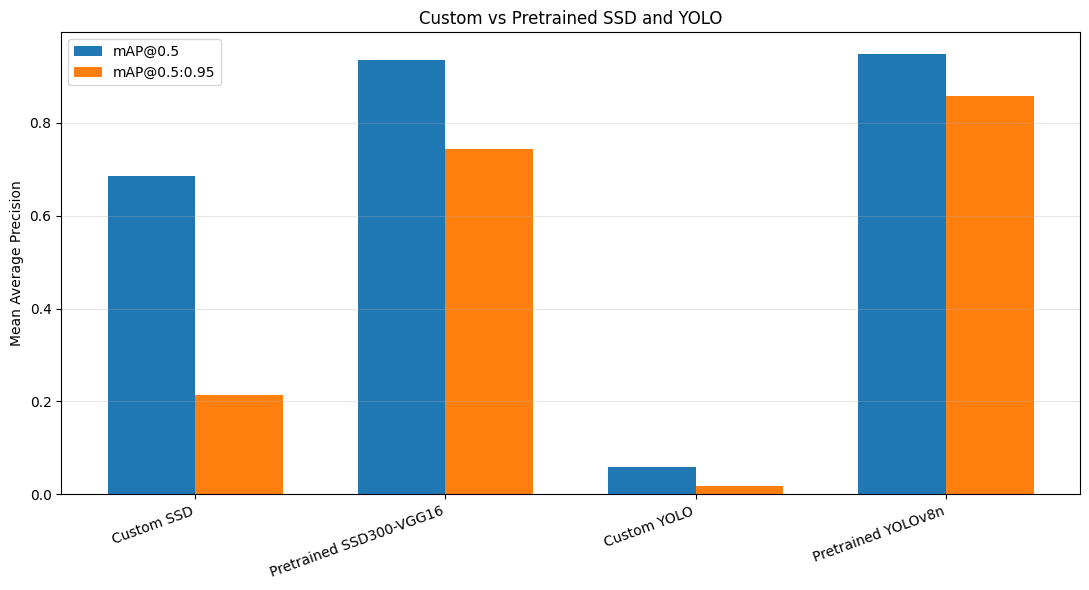

In [40]:
import numpy as np
import matplotlib.pyplot as plt

x = np.arange(len(final_comparison))
width = 0.35

plt.figure(figsize=(11, 6))

plt.bar(
    x - width / 2,
    final_comparison["mAP@0.5"],
    width,
    label="mAP@0.5"
)

plt.bar(
    x + width / 2,
    final_comparison["mAP@0.5:0.95"],
    width,
    label="mAP@0.5:0.95"
)

plt.xticks(
    x,
    final_comparison["Model"],
    rotation=20,
    ha="right"
)

plt.ylabel("Mean Average Precision")
plt.title("Custom vs Pretrained SSD and YOLO")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

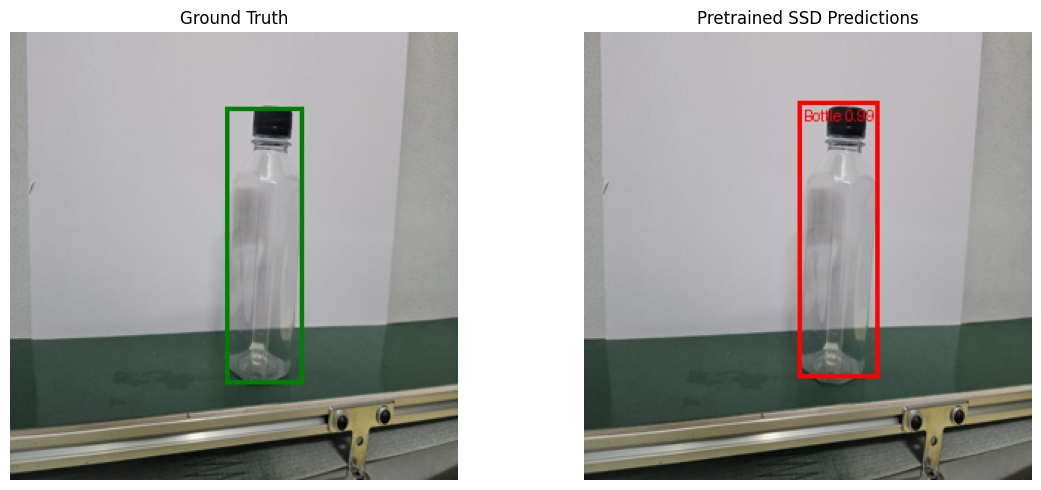

In [41]:
from torchvision.utils import draw_bounding_boxes
from torchvision.transforms.functional import to_pil_image

pretrained_ssd.eval()

image, gt_boxes = ssd_test_dataset[0]

with torch.no_grad():
    output = pretrained_ssd(
        [image.to(device)]
    )[0]

output = {
    k: v.cpu()
    for k, v in output.items()
}

keep = (
    (output["labels"] == SSD_BOTTLE_ID) &
    (output["scores"] >= 0.3)
)

image_uint8 = (
    image * 255
).clamp(0, 255).to(torch.uint8)

H, W = image.shape[-2:]

scale = torch.tensor([W, H, W, H])

gt_pixels = cxcywh_to_xyxy(gt_boxes) * scale

gt_image = draw_bounding_boxes(
    image_uint8,
    gt_pixels,
    colors="green",
    width=3
)

if keep.any():
    pred_image = draw_bounding_boxes(
        image_uint8,
        output["boxes"][keep],
        labels=[
            f"Bottle {score:.2f}"
            for score in output["scores"][keep].tolist()
        ],
        colors="red",
        width=3
    )
else:
    pred_image = image_uint8

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(to_pil_image(gt_image))
axes[0].set_title("Ground Truth")

axes[1].imshow(to_pil_image(pred_image))
axes[1].set_title("Pretrained SSD Predictions")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

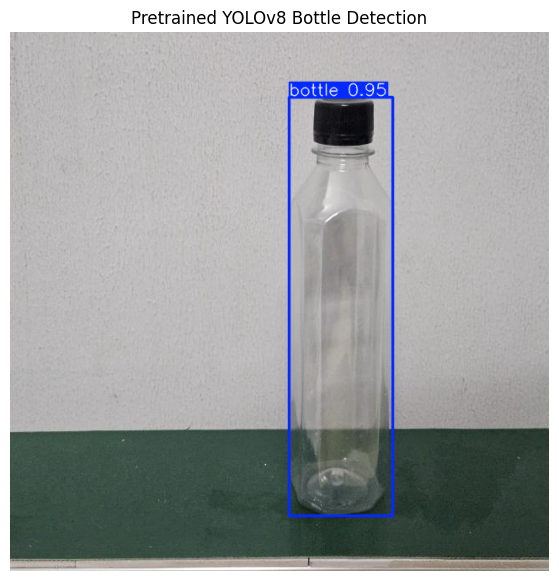

Image: 20260303_182434_jpg.rf.a0532711ab73e2227f047e7251a97bea.jpg
Detected bottles: 1


In [42]:
test_image_path = next(
    iter(sorted((yolo_root / "images" / "test").glob("*")))
)

results = best_yolo.predict(
    source=str(test_image_path),
    conf=0.3,
    save=False,
    verbose=False
)

annotated_image = results[0].plot()

plt.figure(figsize=(10, 7))
plt.imshow(annotated_image[:, :, ::-1])
plt.title("Pretrained YOLOv8 Bottle Detection")
plt.axis("off")
plt.show()

print("Image:", test_image_path.name)
print("Detected bottles:", len(results[0].boxes))

In [43]:
import os

save_dir = "/content/tutorial9_task2_results"
os.makedirs(save_dir, exist_ok=True)

torch.save(
    pretrained_ssd.state_dict(),
    f"{save_dir}/pretrained_ssd_finetuned.pth"
)

final_comparison.to_csv(
    f"{save_dir}/final_model_comparison.csv",
    index=False
)

pd.DataFrame(pretrained_ssd_history).to_csv(
    f"{save_dir}/pretrained_ssd_training.csv",
    index=False
)

shutil.copy2(
    best_yolo_path,
    f"{save_dir}/pretrained_yolov8_best.pt"
)

print("All models and results saved!")

All models and results saved!


## Training Analysis

The pretrained SSD model demonstrated generally decreasing training and validation losses over 10 epochs. Its best validation loss was 1.0027 at epoch 10.

The pretrained YOLOv8n model completed 20 epochs and achieved validation mAP@0.5 of 99.50% and mAP@0.5:0.95 of 94.20% at its selected checkpoint.

Both models successfully adapted their pretrained features to the bottle detection task.

## Performance Comparison

Pretrained SSD substantially outperformed the custom SSD model, improving test mAP@0.5 from 68.52% to 93.55%.

Similarly, pretrained YOLOv8n improved test mAP@0.5 from 5.78% to 94.79%.

The improvements were particularly significant at stricter IoU thresholds, indicating more accurate bounding-box localization.

YOLOv8n achieved the highest overall performance, with 85.89% mAP@0.5:0.95 compared with 74.36% for pretrained SSD.

However, this comparison uses different architectures, training schedules, and model implementations. Therefore, the results demonstrate performance under the tested conditions rather than proving that YOLO is universally superior to SSD.
